# Interpreting results

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Interpreting super-resolved output and its uncertainty
</div>
<!-- markdownlint-enable MD033 -->

---

You produced a single super-resolved patch on the previous page. This page asks how confident the model actually was about the detail it generated, and, just as importantly, what that confidence measure does and does not prove.

---

## 1. Motivation

A super-resolved image looks equally sharp and finished everywhere, whether the model was genuinely confident about a given region or essentially guessing. Uncertainty estimation is what surfaces that hidden difference, and reading it correctly is one of the most important responsible-use skills in this entire lesson.

---

## 2. Core idea

Because the reverse diffusion process starts from random noise, running the model several times on the same input produces slightly different outputs. The **{term}`uncertainty map <Uncertainty Map>`** summarises how much these runs disagree, per pixel: where repeated runs agree closely, the model is consistent; where they disagree, the model is less certain about the fine-scale structure it generated there.

---

## 3. Computing and reading uncertainty

### A. Set up

Start by loading the same Granada scene as on the previous page. If the file was already downloaded there, it is reused rather than downloaded again.

In [1]:
import contextlib
import io
import time
import warnings

import geoai
import numpy as np
import rasterio as rio
from matplotlib import pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore")

DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

url = "https://data.source.coop/giuz/sds320/L09/data/S2A_L2A_20260802_N0512_R094_subset_Granada.tif"
s2_path = geoai.download_file(url, output_path=str(DATA_DIR / Path(url).name))

ROW, COL, SIZE = 700, 1300, 128  # the same patch as on page 5
STEPS = 10                       # sampling steps, as chosen on page 5

### B. Two runs, two images

Before computing any statistic, look at the effect directly: run the model twice on exactly the same input.

In [2]:
runs = []
for i in [1, 2]:
    with contextlib.redirect_stdout(io.StringIO()):  # hide the model's loading messages
        sr, _ = geoai.super_resolution(
            input_lr_path=s2_path,
            output_sr_path=str(OUT_DIR / f"sr_run{i}.tif"),
            window=(ROW, COL, SIZE, SIZE),
            sampling_steps=STEPS,
        )
    runs.append(sr)

diff = np.abs(runs[0][:3] - runs[1][:3]).mean(axis=0)  # mean absolute difference over R, G, B
print(f"Mean difference between the two runs: {diff.mean():.4f} reflectance")
print(f"99th percentile of the difference:    {np.percentile(diff, 99):.4f} reflectance")

Mean difference between the two runs: 0.0116 reflectance
99th percentile of the difference:    0.0746 reflectance


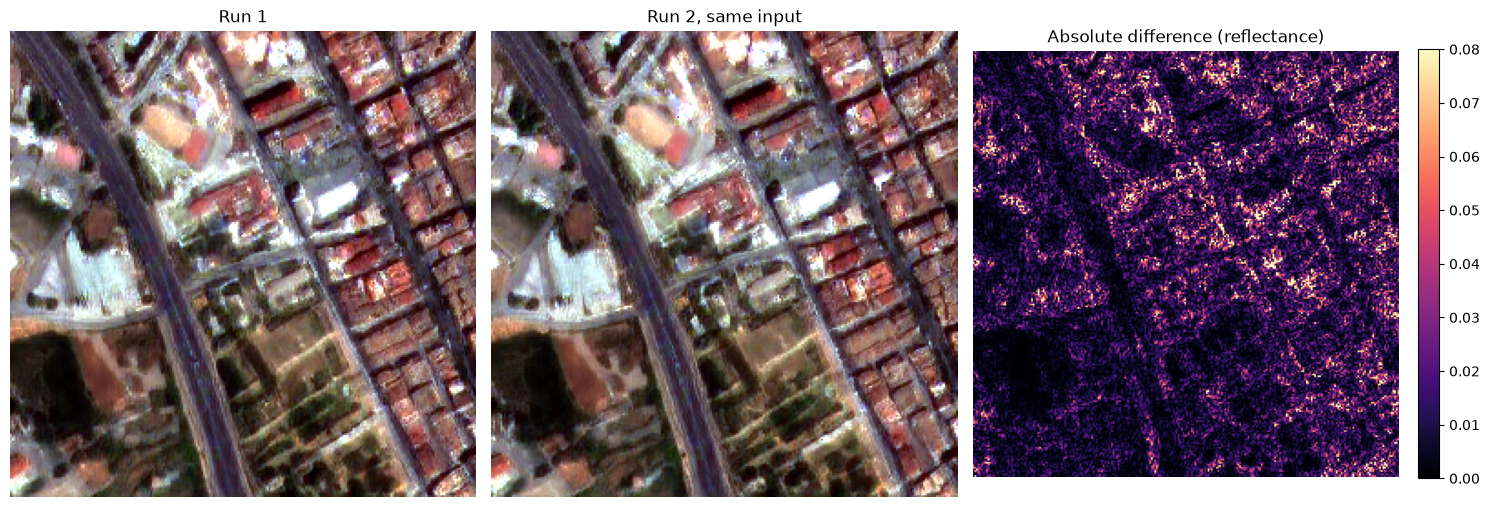

In [3]:
p2 = np.percentile(runs[0][:3], 2, axis=(1, 2), keepdims=True)
p98 = np.percentile(runs[0][:3], 98, axis=(1, 2), keepdims=True)

def show(img):
    """Return an RGB image (height, width, 3) with a shared contrast stretch."""
    return np.clip((img[:3] - p2) / (p98 - p2), 0, 1).transpose(1, 2, 0)

z = (slice(256, 512), slice(256, 512))  # lower-right quarter: dense blocks of flats
fig, axes = plt.subplots(1, 3, figsize=(15, 5.3))
axes[0].imshow(show(runs[0][:, z[0], z[1]]))
axes[0].set_title("Run 1")
axes[1].imshow(show(runs[1][:, z[0], z[1]]))
axes[1].set_title("Run 2, same input")
im = axes[2].imshow(diff[z], cmap="magma", vmin=0, vmax=0.08)
axes[2].set_title("Absolute difference (reflectance)")
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
plt.show()

At first glance the two runs look the same. Look closer at individual roofs, courtyards and the small dark shapes between buildings, and they differ: the difference map lights up along building edges and on individual roofs, while streets of uniform colour stay dark. Neither run is "the" answer; both are plausible images consistent with the same 10 m input. This is the "generated, not observed" idea from page 2, now made visible.

### C. Compute uncertainty

`geoai` automates this comparison: it runs the model several times and stores the spread of the results as an uncertainty map.

In [4]:
sr_unc_output = str(OUT_DIR / "sr_with_uncertainty.tif")
unc_output = str(OUT_DIR / "uncertainty.tif")

start = time.perf_counter()
with contextlib.redirect_stdout(io.StringIO()):
    sr_image, uncertainty = geoai.super_resolution(
        input_lr_path=s2_path,
        output_sr_path=sr_unc_output,
        output_uncertainty_path=unc_output,
        rgb_nir_bands=[1, 2, 3, 4],
        window=(ROW, COL, SIZE, SIZE),
        compute_uncertainty=True,
        n_variations=5,
        sampling_steps=STEPS,
    )
print(f"Uncertainty map shape: {uncertainty.shape}, runtime {time.perf_counter() - start:.0f} s")

Uncertainty map shape: (512, 512), runtime 134 s


`compute_uncertainty=True` enables the repeated-sampling process; `n_variations=5` sets how many additional runs, each with a different random seed, to compare. For every pixel and band, the model computes the standard deviation across these runs, doubles it, and averages over the four bands. The result is in **reflectance units**: the typical width of the range within which the runs fall. The default is `n_variations=25`, and values of 3 or less are rejected, because a standard deviation from so few samples is meaningless. Five is a compromise for teaching: the runtime grows roughly in proportion to `n_variations`.

### D. Visualize the uncertainty map

`geoai` provides a quick plot:

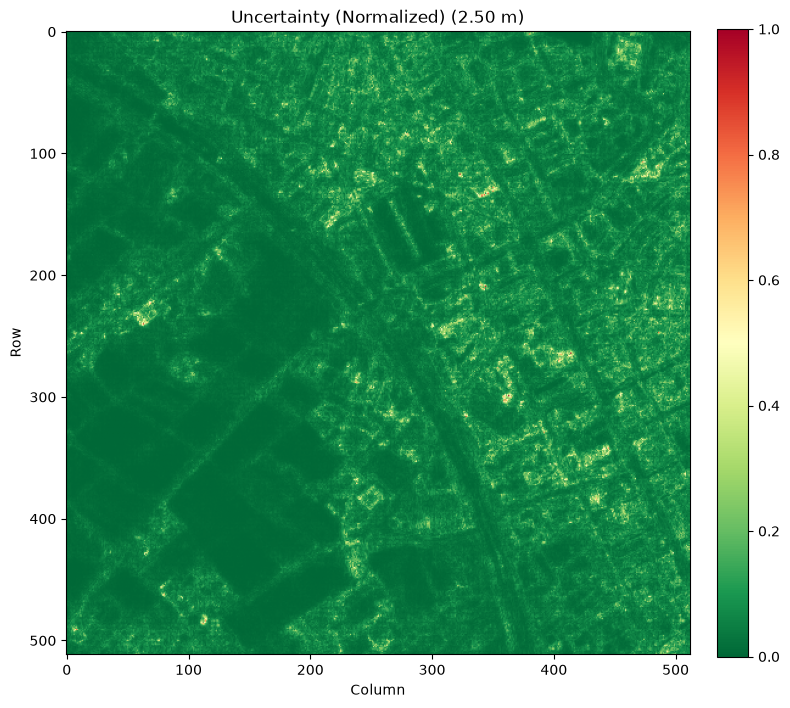

In [5]:
geoai.plot_sr_uncertainty(unc_output)
plt.show()

This plot rescales the values to 0–1 (green = lowest, red = highest in this patch), which makes patterns visible but hides how large the uncertainty actually is. The version below keeps the reflectance units and overlays the most uncertain 10% of pixels on the super-resolved image:

Uncertainty, reflectance: median 0.013, 90th percentile 0.037, 99th percentile 0.083
Median brightness of the image: 0.124
Median uncertainty relative to the local brightness: 11%


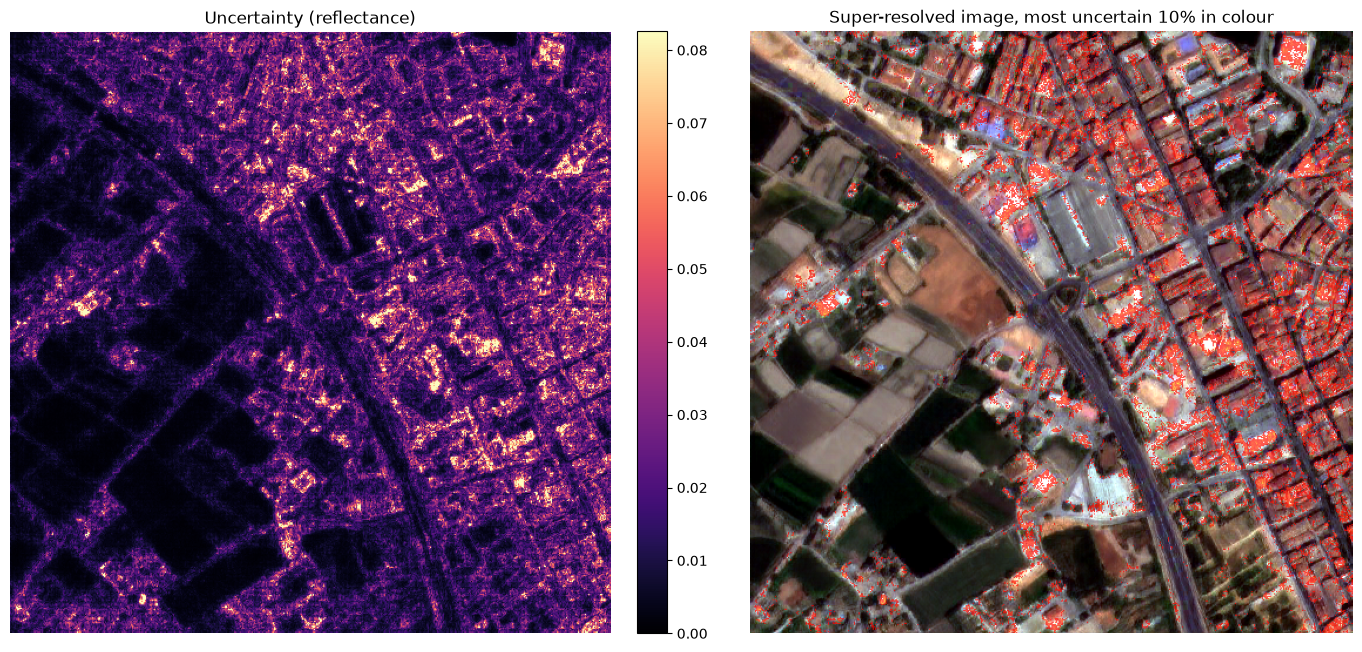

In [6]:
q50, q90, q99 = np.percentile(uncertainty, [50, 90, 99])
print(f"Uncertainty, reflectance: median {q50:.3f}, 90th percentile {q90:.3f}, 99th percentile {q99:.3f}")
rgb_mean = sr_image[:3].mean(axis=0)
print(f"Median brightness of the image: {np.median(rgb_mean):.3f}")
print(f"Median uncertainty relative to the local brightness: {np.median(uncertainty / rgb_mean):.0%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
im = axes[0].imshow(uncertainty, cmap="magma", vmin=0, vmax=q99)
axes[0].set_title("Uncertainty (reflectance)")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

axes[1].imshow(show(sr_image))
axes[1].imshow(np.ma.masked_less(uncertainty, q90), cmap="autumn", alpha=0.7)
axes[1].set_title("Super-resolved image, most uncertain 10% in colour")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
plt.show()

To put the numbers in context: the median uncertainty is about a tenth of the local brightness, so most generated detail varies only slightly between runs. The most uncertain pixels, however, reach several hundredths of reflectance, comparable to the contrast between a roof and the street next to it: in those places the runs disagree about *where* the roof ends. The overlay shows that these pixels are scattered over the dense blocks of flats east of the ring road, while the fields to the west hardly appear.

### E. Where uncertainty concentrates

Rather than judging by eye, group the pixels by the kind of surface they show and compare their uncertainty. The groups use the super-resolved image itself: vegetation by NDVI, bright surfaces by brightness, and "edges" by local contrast.

In [7]:
red, green, blue, nir = sr_image
brightness = (red + green + blue) / 3
ndvi = (nir - red) / (nir + red)
gy, gx = np.gradient(brightness)
edges = np.hypot(gx, gy)

groups = {
    "Vegetation (NDVI > 0.5)": ndvi > 0.5,
    "Bright surfaces (top 10%)": brightness > np.percentile(brightness, 90),
    "Strong edges (top 10%)": edges > np.percentile(edges, 90),
    "Weak edges (bottom 50%)": edges < np.percentile(edges, 50),
    "All pixels": np.ones_like(ndvi, dtype=bool),
}
for name, mask in groups.items():
    print(f"{name:<27} {mask.mean():5.1%} of pixels   mean uncertainty {uncertainty[mask].mean():.4f}")

r_edges = np.corrcoef(uncertainty.ravel(), edges.ravel())[0, 1]
r_runs = np.corrcoef(uncertainty.ravel(), diff.ravel())[0, 1]
print(f"\nCorrelation of uncertainty with edge strength:              {r_edges:.2f}")
print(f"Correlation of uncertainty with the run 1 / run 2 difference: {r_runs:.2f}")

Vegetation (NDVI > 0.5)     20.0% of pixels   mean uncertainty 0.0072
Bright surfaces (top 10%)   10.0% of pixels   mean uncertainty 0.0367
Strong edges (top 10%)      10.0% of pixels   mean uncertainty 0.0383
Weak edges (bottom 50%)     50.0% of pixels   mean uncertainty 0.0103
All pixels                  100.0% of pixels   mean uncertainty 0.0175

Correlation of uncertainty with edge strength:              0.57
Correlation of uncertainty with the run 1 / run 2 difference: 0.55


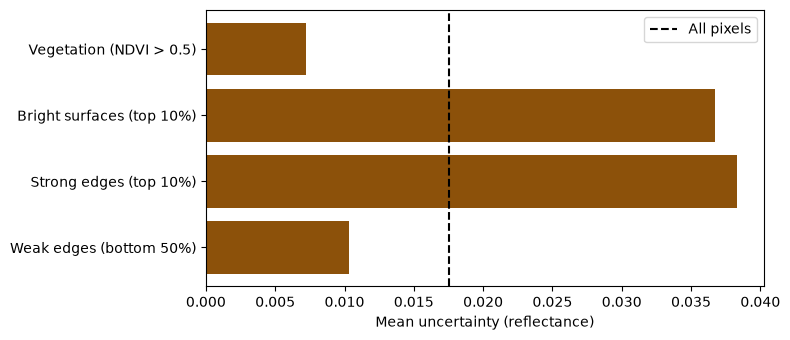

In [8]:
names = list(groups)[:-1]
values = [uncertainty[groups[n]].mean() for n in names]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(names, values, color="#8c510a")
ax.axvline(uncertainty.mean(), color="black", linestyle="--", label="All pixels")
ax.set_xlabel("Mean uncertainty (reflectance)")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.show()

The numbers support a clear pattern. Uncertainty is highest at **strong edges**, such as building outlines and the borders between roofs and courtyards, and on **bright surfaces**, such as light roofs, sports courts and warehouse roofs, where small shifts of an edge change the reflectance a lot. It is lowest on **vegetation** and wherever the image has little local contrast, such as the irrigated fields west of the ring road, where there is little fine-scale structure for the model to invent. The uncertainty map also correlates with the difference between the two independent runs from step B, which is reassuring: it measures exactly the run-to-run variation you saw there.

Note that the ring road itself is not especially uncertain, although it is a sharp feature: it is several 10 m pixels wide, so its edges are already visible in the input. Uncertainty is high where the *input* is ambiguous about what lies beneath, typically structures smaller than one or two 10 m pixels.

### F. What uncertainty does not tell you

```{admonition} Low uncertainty is not proof of correctness
:class: warning
A model can be confidently wrong: producing a sharp, consistent feature across every stochastic run that nonetheless does not match what actually exists on the ground. Uncertainty tells you how consistent the model's repeated guesses were with each other, not whether any of them are correct. A model trained on images of the United States (page 8) may consistently draw the same kind of roof on every run, whether or not Granada's roofs look like that. Treat a low-uncertainty region as "the model was consistent here," not as "this is verified." Page 7 compares the output with real aerial imagery.
```

---

## 4. Python reactivation

- `red, green, blue, nir = sr_image` unpacks the first axis of a NumPy array into separate variables, one 2D band each.
- `np.percentile(x, [50, 90, 99])` returns several percentiles at once; the result can be unpacked into separate variables.
- Comparisons such as `ndvi > 0.5` create Boolean **masks**; `uncertainty[mask]` selects only the pixels where the mask is `True`, and `mask.mean()` is the share of `True` pixels.
- `np.ma.masked_less(uncertainty, q90)` hides all values below a threshold, so only the remaining pixels are drawn on top of the image.
- `np.corrcoef(a.ravel(), b.ravel())[0, 1]` computes the correlation coefficient between two images, flattened into 1D arrays.

---

## 5. Common pitfalls

- **Treating low uncertainty as proof of correctness.** This is the single most important pitfall in this lesson; low uncertainty means consistent, not necessarily correct.
- **Assuming all high-uncertainty regions represent errors.** Some genuinely are ambiguous, hard-to-resolve areas where caution is warranted; the map flags where to look carefully, not automatically what is wrong.
- **Reading normalized maps as absolute.** `plot_sr_uncertainty()` stretches every map to 0–1; red in one patch and red in another patch can mean very different amounts of uncertainty. Compare the values in reflectance.
- **Choosing `n_variations` without considering the time cost.** More variations make the estimate more reliable but scale processing time roughly proportionally; values of 3 or less are rejected.
- **Skipping uncertainty estimation entirely for a project deliverable.** If super-resolved imagery informs a project conclusion, the uncertainty map is part of the evidence needed to interpret that conclusion responsibly, not an optional add-on.

---

## 6. Mini task

You compute an uncertainty map for a patch containing a dense residential neighborhood and a large, uniform lake. Predict, before looking, which region will likely show higher uncertainty, and explain why using the measurements from step E.

:::{dropdown} Sample solution
:class: note

The residential neighborhood is likely to show higher uncertainty. It contains strong edges (building outlines, courtyards, property boundaries) and bright roofs smaller than a 10 m pixel, the groups with the highest mean uncertainty in step E. The uniform lake is homogeneous, with little fine-scale structure to reconstruct, so repeated runs are likely to agree closely there, like the weak-edge group and the fields in step E.

Two cautions: lake shores are edges and may show higher uncertainty than the open water; and low uncertainty on the lake would mean only that the runs agreed, not that every detail on the water surface is correct.
:::

---

## 7. Key takeaways

- Two runs on the same input give two different, equally plausible images; the uncertainty map measures that spread across several runs.
- `geoai` computes it as twice the per-pixel standard deviation across `n_variations` runs, averaged over the four bands, in reflectance units.
- In Granada, uncertainty is highest at strong edges and bright surfaces, and lowest on vegetation and homogeneous fields; wide features visible in the input, such as the ring road, stay low.
- Low uncertainty means the model was consistent across runs, not that its output is correct; a model can be confidently wrong.
- `n_variations` trades estimate reliability against processing time; the default is 25, and the minimum is 4.

### Further reading

- Donike, Aybar, Gómez-Chova and Kalaitzis (2025), ["Trustworthy Super-Resolution of Multispectral Sentinel-2 Imagery With Latent Diffusion"](https://doi.org/10.1109/JSTARS.2025.3542220), IEEE JSTARS — the LDSR-S2 paper, including how its uncertainty maps are derived.